# 🤖 Tarea 1 – Parte 2: Del LLM al clasificador

**Pregunta guía:** ¿Pueden convertir titulares peruanos en un clasificador de noticias?

**Diseño experimental**

| Paso | Qué se hace | Datos |
| :--- | :--- | :--- |
| 0 | Split estratificado 70/15/15 (`random_state=42`) **antes de todo**; el test queda aislado | `datos/noticias.csv` (400) |
| 1 | Línea base zero-shot `Recognai/bert-base-spanish-wwm-cased-xnli` | 40 titulares del test |
| 2 | Supervisión débil: `qwen2.5:7b` (Ollama, local) etiqueta las 400 noticias + auditoría humana de 20 casos | dataset completo |
| 3 | Fine-tuning de `distilbert-base-multilingual-cased` **entrenado con las etiquetas del LLM** | train (70%) / val (15%) |
| 4 | Evaluación final contra la **etiqueta de sección del diario** (verdad de referencia) | test (15%) |

> La entrada de todos los modelos es **solo el titular**, porque el dashboard clasifica titulares sueltos.
> El LLM recibe además la bajada para etiquetar con más contexto (es el "anotador" débil).

In [1]:
import json
import os
import time

# La descarga por protocolo "xet" de Hugging Face falló (404) en este equipo; se usa la descarga HTTP clásica
os.environ.setdefault("HF_HUB_DISABLE_XET", "1")
from datetime import datetime, timedelta, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import torch
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          Trainer, TrainingArguments, pipeline, set_seed)
import transformers

transformers.logging.set_verbosity_error()   # salidas limpias: sin avisos ni barras de carga de pesos
transformers.logging.disable_progress_bar()

SEMILLA = 42
set_seed(SEMILLA)
torch.set_num_threads(max(1, torch.get_num_threads()))
pd.set_option("display.max_colwidth", 110)

CATEGORIAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
ID2LABEL = dict(enumerate(CATEGORIAS))
LABEL2ID = {v: k for k, v in ID2LABEL.items()}
DIR_DATOS, DIR_MODELO = Path("datos"), Path("modelo")
DIR_MODELO.mkdir(exist_ok=True)

print("torch", torch.__version__, "| transformers", transformers.__version__,
      "| dispositivo:", "cuda" if torch.cuda.is_available() else "cpu", f"({torch.get_num_threads()} hilos)")

df = pd.read_csv(DIR_DATOS / "noticias.csv")
print(df.shape)
pd.crosstab(df["etiqueta"], df["medio"])

D:\diplomatura\python-intermedio-qlab\tarea_1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.14.1+cpu | transformers 5.20.1 | dispositivo: cpu (4 hilos)
(400, 7)


medio,El Comercio,La Republica
etiqueta,,
ciencia_tecnologia,50,50
deportes,50,50
economia,50,50
politica,50,50


## 0. Partición 70 / 15 / 15 estratificada (`random_state=42`)

Se estratifica por **categoría × medio** (8 estratos de 50), lo que garantiza la misma proporción de categorías
—y de medios— en cada partición. El conjunto de **test no se vuelve a tocar hasta la sección 4**
(salvo los 40 titulares de la línea base zero-shot, que no entrena nada).

In [2]:
estrato = df["etiqueta"] + "|" + df["medio"]
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=estrato, random_state=SEMILLA)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=estrato[temp_df.index], random_state=SEMILLA)

particion = pd.Series("train", index=df.index)
particion[val_df.index], particion[test_df.index] = "val", "test"
df[["url", "medio", "etiqueta"]].assign(particion=particion).to_csv(DIR_DATOS / "split.csv", index=False)

assert set(train_df.url).isdisjoint(test_df.url) and set(val_df.url).isdisjoint(test_df.url)
resumen_split = pd.DataFrame({p: d["etiqueta"].value_counts() for p, d in
                              [("train", train_df), ("val", val_df), ("test", test_df)]}).loc[CATEGORIAS]
resumen_split.loc["TOTAL"] = resumen_split.sum()
print({p: f"{len(d)} ({len(d) / len(df):.0%})" for p, d in [("train", train_df), ("val", val_df), ("test", test_df)]})
resumen_split

{'train': '280 (70%)', 'val': '60 (15%)', 'test': '60 (15%)'}


,train,val,test
etiqueta,,,
politica,70,15,15
economia,70,15,15
deportes,70,14,16
ciencia_tecnologia,70,16,14
TOTAL,280,60,60


## 1. Línea base zero-shot (sin fine-tuning)

Se evalúan **40 titulares del conjunto de test** (10 por categoría, muestreo con semilla fija) con
`Recognai/bert-base-spanish-wwm-cased-xnli`. Las etiquetas candidatas se escriben en lenguaje natural para que el
modelo NLI pueda razonar sobre ellas.

In [3]:
ZS_MODELO = "Recognai/bert-base-spanish-wwm-cased-xnli"
ZS_ETIQUETAS = {"política": "politica", "economía": "economia", "deportes": "deportes",
                "ciencia y tecnología": "ciencia_tecnologia"}

zs_df = test_df.groupby("etiqueta", group_keys=False).sample(10, random_state=SEMILLA)
zero_shot = pipeline("zero-shot-classification", model=ZS_MODELO, device=-1)

t0 = time.perf_counter()
salidas = zero_shot(zs_df["titular"].tolist(), candidate_labels=list(ZS_ETIQUETAS),
                    hypothesis_template="Esta noticia trata sobre {}.")
zs_latencia_ms = (time.perf_counter() - t0) / len(zs_df) * 1000

zs_df = zs_df.assign(pred_zs=[ZS_ETIQUETAS[s["labels"][0]] for s in salidas],
                     score_zs=[s["scores"][0] for s in salidas])
zs_acc = accuracy_score(zs_df["etiqueta"], zs_df["pred_zs"])
zs_f1 = f1_score(zs_df["etiqueta"], zs_df["pred_zs"], average="macro")
print(f"ZERO-SHOT (40 titulares de test) → Accuracy: {zs_acc:.3f} | F1 macro: {zs_f1:.3f} | {zs_latencia_ms:.0f} ms/titular")
print(classification_report(zs_df["etiqueta"], zs_df["pred_zs"], labels=CATEGORIAS, zero_division=0))

ZERO-SHOT (40 titulares de test) → Accuracy: 0.725 | F1 macro: 0.716 | 598 ms/titular
                    precision    recall  f1-score   support

          politica       0.56      1.00      0.71        10
          economia       0.67      0.40      0.50        10
          deportes       0.90      0.90      0.90        10
ciencia_tecnologia       1.00      0.60      0.75        10

          accuracy                           0.72        40
         macro avg       0.78      0.72      0.72        40
      weighted avg       0.78      0.72      0.72        40



In [4]:
zs_df.loc[zs_df["etiqueta"] != zs_df["pred_zs"], ["titular", "etiqueta", "pred_zs", "score_zs"]].head(10)

,titular,etiqueta,pred_zs,score_zs
23,Meta afirma que unos ‘hackers’ accedieron a su GitHub y expusieron datos personales de 1.500 personas,ciencia_tecnologia,politica,0.339517
216,Nuevo hallazgo sobre el Alzheimer: las personas con esta enfermedad presentaban estos síntomas años antes ...,ciencia_tecnologia,economia,0.256749
28,Meta presenta nuevo modelo de IA y afirma que está al nivel de OpenAI y Anthropic,ciencia_tecnologia,deportes,0.485234
7,"iPhone Duo se agota a minutos de abierta su preventa, ahora disponibles a partir del 22 de enero",ciencia_tecnologia,economia,0.337268
98,"Mourinho sorprende con mensaje sobre Vinícius: “Si estuviese en su lugar, probablemente no estaría aquí”",deportes,politica,0.439763
306,Produce cierra el 2026 sin segunda temporada de anchoveta y la SNP pide apoyo al Gobierno,economia,politica,0.353040
334,"Precio del dólar hoy en Perú, domingo 27 de septiembre: consulta el tipo de cambio para compra y venta",economia,politica,0.365046
116,"De consultar saldos a delegar operaciones, ¿cómo cambiará la banca con la IA hacia 2030?",economia,politica,0.462383
322,"Precio del dólar hoy en Perú, jueves 8 de octubre: consulta el tipo de cambio para compra y venta",economia,politica,0.384916
329,"Minem entra en reorganización: Gobierno identifica fallas en inversiones, trámites y gestión de conflictos",economia,politica,0.549694


Este F1 macro es el **piso mínimo** que deben superar los modelos siguientes.

## 2. Supervisión débil con un LLM local (Ollama + `qwen2.5:7b`)

- Prompt estructurado con definición operativa de cada categoría.
- Salida forzada con **JSON Schema** (`format` de Ollama): `categoria` ∈ {4 categorías} y `confianza` ∈ [0, 1].
- `temperature=0` y `seed=42` para que el etiquetado sea reproducible.
- Se etiqueta el **dataset completo**; las etiquetas se guardan en `datos/etiquetas_llm.csv` y se reutilizan si ya existen.

> La `confianza` es **autodeclarada por el LLM** (no es una probabilidad calibrada); se usa como indicador relativo.

In [5]:
OLLAMA_URL = "http://localhost:11434/api/chat"
MODELO_LLM = "qwen2.5:7b"

PROMPT_SISTEMA = """Eres editor de un diario peruano y clasificas noticias por su tema principal.
Elige EXACTAMENTE una de estas 4 categorías:
- politica: Gobierno, Presidencia, ministros, Congreso, partidos, elecciones, JNE/ONPE, Poder Judicial y Fiscalía cuando involucran a autoridades, política internacional y relaciones entre Estados.
- economia: mercados, empresas, precios, dólar, inflación, empleo, sueldos, impuestos, AFP/ONP/CTS, bonos, bancos, finanzas personales, comercio, minería y energía como actividad económica.
- deportes: fútbol, vóley y cualquier disciplina deportiva; clubes, selecciones, deportistas, partidos, resultados, fichajes y transmisiones.
- ciencia_tecnologia: ciencia, investigación, salud desde la ciencia, espacio, naturaleza, animales, medio ambiente, tecnología, internet, inteligencia artificial, celulares, apps, videojuegos y ciberseguridad.
Si la noticia mezcla temas, elige el tema central del titular.
Responde solo con JSON: {"categoria": <una de las 4>, "confianza": <número entre 0 y 1>}."""

ESQUEMA = {"type": "object",
           "properties": {"categoria": {"type": "string", "enum": CATEGORIAS},
                          "confianza": {"type": "number", "minimum": 0, "maximum": 1}},
           "required": ["categoria", "confianza"]}


def etiquetar_llm(titular, bajada=""):
    contenido = f"Titular: {titular}" + (f"\nBajada: {bajada}" if bajada else "")
    payload = {"model": MODELO_LLM, "stream": False, "format": ESQUEMA, "keep_alive": "30m",
               "options": {"temperature": 0, "seed": SEMILLA},
               "messages": [{"role": "system", "content": PROMPT_SISTEMA}, {"role": "user", "content": contenido}]}
    r = requests.post(OLLAMA_URL, json=payload, timeout=300)
    r.raise_for_status()
    salida = json.loads(r.json()["message"]["content"])
    return salida["categoria"], float(salida["confianza"])

In [6]:
ruta_llm = DIR_DATOS / "etiquetas_llm.csv"
if ruta_llm.exists():
    llm_df = pd.read_csv(ruta_llm)
    print(f"Se reutilizan {len(llm_df)} etiquetas existentes de {ruta_llm} (modelo {llm_df['modelo_llm'].iloc[0]})")
else:
    filas, t0 = [], time.perf_counter()
    for i, fila in enumerate(df.itertuples(), 1):
        cat, conf = etiquetar_llm(fila.titular, fila.bajada)
        filas.append({"titular": fila.titular, "etiqueta_llm": cat, "confianza": round(conf, 3),
                      "modelo_llm": f"ollama/{MODELO_LLM}",
                      "fecha": datetime.now(timezone(timedelta(hours=-5))).strftime("%Y-%m-%d"),
                      "url": fila.url})
        if i % 50 == 0:
            print(f"  {i}/{len(df)} etiquetadas ({(time.perf_counter() - t0) / i:.1f} s/noticia)")
    llm_df = pd.DataFrame(filas)
    llm_df.to_csv(ruta_llm, index=False, encoding="utf-8")
    print(f"Etiquetado completo en {(time.perf_counter() - t0) / 60:.1f} min → {ruta_llm}")

# Latencia del LLM medida aparte sobre 10 titulares (solo titular, como en el dashboard)
t0 = time.perf_counter()
for t in test_df["titular"].head(10):
    etiquetar_llm(t)
llm_latencia_ms = (time.perf_counter() - t0) / 10 * 1000
print(f"Latencia LLM: {llm_latencia_ms:.0f} ms/titular")

llm_df = llm_df.set_index("url").loc[df["url"]].reset_index()  # mismo orden que df
df["etiqueta_llm"], df["confianza_llm"] = llm_df["etiqueta_llm"].values, llm_df["confianza"].values
llm_df.head()

Se reutilizan 400 etiquetas existentes de datos\etiquetas_llm.csv (modelo ollama/qwen2.5:7b)


Latencia LLM: 6313 ms/titular


,url,titular,etiqueta_llm,confianza,modelo_llm,fecha
0,https://elcomercio.pe/tecnologia/actualidad/tesla-presenta-un-roadster-capaz-de-volar-y-en-las-redes-socia...,Tesla presenta un Roadster capaz de ‘volar’ y en las redes sociales lo reciben con memes,ciencia_tecnologia,0.90,ollama/qwen2.5:7b,2026-10-18
1,https://elcomercio.pe/tecnologia/robotica/alemania-investiga-una-presunta-agresion-sexual-con-un-robot-con...,Alemania investiga una presunta agresión sexual con un robot contra joven de 16 años,ciencia_tecnologia,0.95,ollama/qwen2.5:7b,2026-10-18
2,https://elcomercio.pe/tecnologia/inteligencia-artificial/padre-de-la-ia-y-otros-224-cientificos-piden-camb...,Padre de la IA y otros 224 científicos piden “cambios inmediatos” para su desarrollo y despliegue,ciencia_tecnologia,1.00,ollama/qwen2.5:7b,2026-10-18
3,https://elcomercio.pe/tecnologia/ciencias/salvia-messii-descubren-en-los-andes-peruanos-una-nueva-flor-y-l...,Descubren en los Andes peruanos una nueva flor y la bautizan en honor a Lionel Messi,ciencia_tecnologia,0.80,ollama/qwen2.5:7b,2026-10-18
4,https://elcomercio.pe/tecnologia/ciberseguridad/estafas-digitales-contra-adultos-mayores-seis-recomendacio...,Estafas digitales contra adultos mayores: seis recomendaciones para proteger a padres y abuelos,ciencia_tecnologia,0.95,ollama/qwen2.5:7b,2026-10-18


### Calidad de las etiquetas débiles frente a la sección del diario

In [7]:
llm_acc_total = accuracy_score(df["etiqueta"], df["etiqueta_llm"])
llm_f1_total = f1_score(df["etiqueta"], df["etiqueta_llm"], average="macro")
print(f"LLM vs. sección del diario (400 noticias) → Accuracy: {llm_acc_total:.3f} | F1 macro: {llm_f1_total:.3f}")
print(classification_report(df["etiqueta"], df["etiqueta_llm"], labels=CATEGORIAS, zero_division=0))
display(pd.crosstab(df["etiqueta"], df["etiqueta_llm"], rownames=["sección del diario"], colnames=["LLM"]))
df.groupby(df["etiqueta"] == df["etiqueta_llm"])["confianza_llm"].describe().rename(index={True: "coincide", False: "no coincide"})

LLM vs. sección del diario (400 noticias) → Accuracy: 0.925 | F1 macro: 0.926
                    precision    recall  f1-score   support

          politica       0.81      1.00      0.89       100
          economia       0.93      0.85      0.89       100
          deportes       1.00      0.95      0.97       100
ciencia_tecnologia       1.00      0.90      0.95       100

          accuracy                           0.93       400
         macro avg       0.94      0.92      0.93       400
      weighted avg       0.94      0.93      0.93       400



LLM,ciencia_tecnologia,deportes,economia,politica
sección del diario,,,,
ciencia_tecnologia,90,0,6,4
deportes,0,95,0,5
economia,0,0,85,15
politica,0,0,0,100


,count,mean,std,min,25%,50%,75%,max
no coincide,30.0,0.908333,0.061705,0.8,0.85,0.95,0.95,0.95
coincide,370.0,0.956622,0.057999,0.8,0.95,0.95,1.00,1.00


### Auditoría humana de 20 predicciones al azar

Se toman 20 noticias al azar (`random_state=42`) y una persona asigna la categoría correcta leyendo titular y bajada,
**sin mirar la etiqueta del LLM ni la sección del diario**. El archivo `datos/auditoria_humana.csv` documenta cada caso.

In [8]:
ruta_auditoria = DIR_DATOS / "auditoria_humana.csv"
if not ruta_auditoria.exists():
    df.sample(20, random_state=SEMILLA)[["url", "titular", "bajada", "etiqueta_llm"]].assign(
        etiqueta_humana="", comentario="").to_csv(ruta_auditoria, index=False, encoding="utf-8")
    print("Se creó la plantilla de auditoría: completar la columna 'etiqueta_humana'.")

auditoria = pd.read_csv(ruta_auditoria).fillna({"etiqueta_humana": "", "comentario": ""})
completa = auditoria["etiqueta_humana"].isin(CATEGORIAS).all()
if completa:
    auditoria["acuerdo"] = auditoria["etiqueta_humana"] == auditoria["etiqueta_llm"]
    acuerdos = int(auditoria["acuerdo"].sum())
    acuerdo_pct = acuerdos / len(auditoria) * 100
    print(f"ACUERDO LLM–HUMANO: {acuerdos}/{len(auditoria)} = {acuerdo_pct:.0f}%")
else:
    acuerdos, acuerdo_pct = None, None
    print("Auditoría pendiente: faltan etiquetas humanas.")
auditoria[["titular", "etiqueta_llm", "etiqueta_humana", "comentario"]]

ACUERDO LLM–HUMANO: 18/20 = 90%


,titular,etiqueta_llm,etiqueta_humana,comentario
0,Científicos descubren una nueva especie de flor albiceleste en los andes peruanos y la nombraron en honor ...,ciencia_tecnologia,ciencia_tecnologia,Ciencia (botánica) aunque mencione a Messi
1,¡Perú clasificó al Mundial! Las 'Matadorcitas' vencieron 3-2 a Brasil y lograron el pase a la final del Su...,deportes,deportes,
2,"Demetrio Pacheco, defensor ambiental en Perú: “El Estado podría haber evitado el asesinato de mi hijo” | E...",politica,politica,"Ambiguo: tema ambiental, pero el foco es la responsabilidad del Estado"
3,Un lagarto de la época de los dinosaurios perdió su cola hace 99 millones de años y el ámbar conservó la e...,ciencia_tecnologia,ciencia_tecnologia,
4,Bayern Múnich vs. Leipzig (6-1): resumen y goles del partido por la Bundesliga | VIDEO,deportes,deportes,
5,¡De otro planeta! Lionel Messi marcó doblete en el duelo de Inter Miami vs. Atlanta United por MLS | VIDEO,deportes,deportes,
6,"Minem entra en reorganización: Gobierno identifica fallas en inversiones, trámites y gestión de conflictos",politica,politica,Ambiguo: reorganización de un ministerio (gestión de gobierno) con impacto en inversión minera
7,Barcelona 5-2 Real Betis: ver resumen y goles ddel partido por LaLiga 2026,deportes,deportes,
8,Universitario - Palmeiras: a qué hora y dónde ver el partido por la fecha 1 de la Copa Libertadores Femeni...,deportes,deportes,
9,Elmer Cuba: “Tenemos un Ministerio de Economía que va a responder para que la economía no se enfríe”,politica,economia,


## 3. Fine-tuning de `distilbert-base-multilingual-cased` con las etiquetas del LLM

- **Train y val usan `etiqueta_llm`** (supervisión débil): así se mide si un modelo pequeño puede *destilar* el
  conocimiento del LLM. El test se evalúa contra la **etiqueta de sección del diario**.
- `HuggingFace Trainer`: 5 épocas (mínimo pedido: 3), batch 16, evaluación por época y selección del mejor
  checkpoint por **F1 macro en validación**.

In [9]:
MODELO_BASE = "distilbert-base-multilingual-cased"
tokenizer = AutoTokenizer.from_pretrained(MODELO_BASE)


class Titulares(torch.utils.data.Dataset):
    def __init__(self, textos, etiquetas):
        self.enc = tokenizer(list(textos), truncation=True, max_length=64)
        self.labels = [LABEL2ID[e] for e in etiquetas]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        item = {k: torch.tensor(v[i]) for k, v in self.enc.items()}
        item["labels"] = torch.tensor(self.labels[i])
        return item


train_df = train_df.assign(etiqueta_llm=df.loc[train_df.index, "etiqueta_llm"])
val_df = val_df.assign(etiqueta_llm=df.loc[val_df.index, "etiqueta_llm"])
ds_train = Titulares(train_df["titular"], train_df["etiqueta_llm"])
ds_val = Titulares(val_df["titular"], val_df["etiqueta_llm"])
ds_test = Titulares(test_df["titular"], test_df["etiqueta"])  # verdad de referencia, solo para la evaluación final
print(f"train={len(ds_train)}  val={len(ds_val)}  test={len(ds_test)}")
print("Distribución de etiquetas LLM en train:", train_df["etiqueta_llm"].value_counts().to_dict())


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds), "f1_macro": f1_score(labels, preds, average="macro")}


modelo = AutoModelForSequenceClassification.from_pretrained(
    MODELO_BASE, num_labels=len(CATEGORIAS), id2label=ID2LABEL, label2id=LABEL2ID)

args = TrainingArguments(
    output_dir="resultados_trainer",
    num_train_epochs=5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=5e-5,
    weight_decay=0.01,
    warmup_steps=0.1,  # en transformers 5 un float < 1 es la proporción de pasos de calentamiento
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    save_total_limit=1,
    seed=SEMILLA,
    report_to="none",
)
trainer = Trainer(model=modelo, args=args, train_dataset=ds_train, eval_dataset=ds_val,
                  processing_class=tokenizer, data_collator=DataCollatorWithPadding(tokenizer),
                  compute_metrics=compute_metrics)

t0 = time.perf_counter()
trainer.train()
minutos_entrenamiento = (time.perf_counter() - t0) / 60
print(f"Entrenamiento en CPU: {minutos_entrenamiento:.1f} min")

train=280  val=60  test=60
Distribución de etiquetas LLM en train: {'politica': 84, 'deportes': 67, 'economia': 67, 'ciencia_tecnologia': 62}


D:\diplomatura\python-intermedio-qlab\tarea_1\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


{'loss': '1.256', 'grad_norm': '3.537', 'learning_rate': '4.506e-05', 'epoch': '1'}


{'eval_loss': '0.934', 'eval_accuracy': '0.7333', 'eval_f1_macro': '0.7286', 'eval_runtime': '2.966', 'eval_samples_per_second': '20.23', 'eval_steps_per_second': '0.674', 'epoch': '1'}


D:\diplomatura\python-intermedio-qlab\tarea_1\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


...

D:\diplomatura\python-intermedio-qlab\tarea_1\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


{'loss': '0.04922', 'grad_norm': '0.3454', 'learning_rate': '6.173e-07', 'epoch': '5'}


{'eval_loss': '0.4909', 'eval_accuracy': '0.85', 'eval_f1_macro': '0.8533', 'eval_runtime': '2.761', 'eval_samples_per_second': '21.73', 'eval_steps_per_second': '0.724', 'epoch': '5'}


{'train_runtime': '266.8', 'train_samples_per_second': '5.248', 'train_steps_per_second': '0.337', 'train_loss': '0.4416', 'epoch': '5'}


Entrenamiento en CPU: 4.5 min


,train_loss,val_loss,val_accuracy,val_f1_macro
epoch,,,,
1.0,1.2562,0.9340,0.7333,0.7286
2.0,0.5747,0.5320,0.8000,0.8062
3.0,0.2226,0.4918,0.8333,0.8385
4.0,0.1051,0.4108,0.8667,0.8692
5.0,0.0492,0.4909,0.8500,0.8533


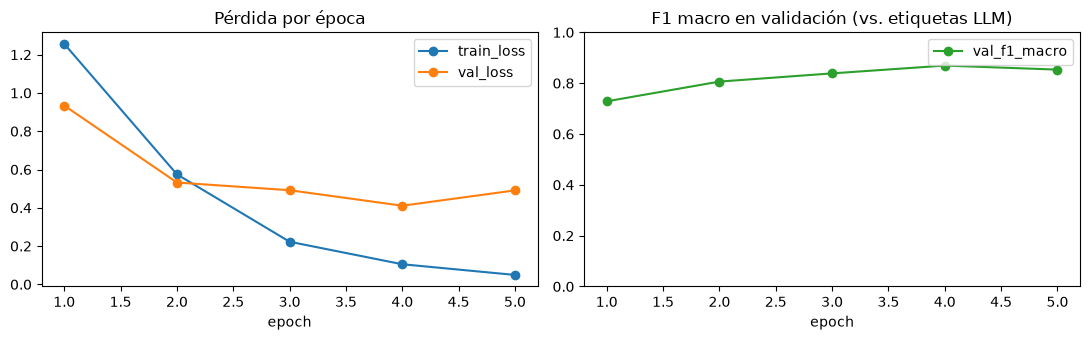

D:\diplomatura\python-intermedio-qlab\tarea_1\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Mejor checkpoint: resultados_trainer\checkpoint-72
F1 macro val vs. etiquetas LLM: 0.869 | vs. sección del diario: 0.901


In [10]:
historial = pd.DataFrame(trainer.state.log_history)
por_epoca = (historial.groupby("epoch")
             .agg(train_loss=("loss", "first"), val_loss=("eval_loss", "first"),
                  val_accuracy=("eval_accuracy", "first"), val_f1_macro=("eval_f1_macro", "first"))
             .dropna(how="all").round(4))
display(por_epoca)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
por_epoca[["train_loss", "val_loss"]].plot(ax=ax[0], marker="o", title="Pérdida por época")
por_epoca[["val_f1_macro"]].plot(ax=ax[1], marker="o", color="tab:green", title="F1 macro en validación (vs. etiquetas LLM)")
ax[1].set_ylim(0, 1)
plt.tight_layout()
plt.show()

val_pred = np.argmax(trainer.predict(ds_val).predictions, axis=-1)
print("Mejor checkpoint:", trainer.state.best_model_checkpoint)
print(f"F1 macro val vs. etiquetas LLM: {f1_score(val_df['etiqueta_llm'].map(LABEL2ID), val_pred, average='macro'):.3f}"
      f" | vs. sección del diario: {f1_score(val_df['etiqueta'].map(LABEL2ID), val_pred, average='macro'):.3f}")

In [11]:
trainer.save_model(DIR_MODELO)
tokenizer.save_pretrained(DIR_MODELO)
print("Archivos en modelo/:")
for f in sorted(DIR_MODELO.iterdir()):
    print(f"  {f.name:<28} {f.stat().st_size / 1e6:8.1f} MB")

Archivos en modelo/:
  config.json                       0.0 MB
  metricas.json                     0.0 MB
  model.safetensors               541.3 MB
  tokenizer.json                    2.9 MB
  tokenizer_config.json             0.0 MB
  training_args.bin                 0.0 MB


> `model.safetensors` pesa más de 100 MB y está excluido en `.gitignore`; en el repositorio solo quedan
> la configuración, el tokenizer y las métricas. El modelo se regenera ejecutando este notebook.

## 4. Evaluación final en el conjunto de test reservado

In [12]:
salida_test = trainer.predict(ds_test)
probs_test = torch.softmax(torch.tensor(salida_test.predictions), dim=-1).numpy()
test_df = test_df.assign(pred_ft=[ID2LABEL[i] for i in probs_test.argmax(1)], prob_ft=probs_test.max(1),
                         etiqueta_llm=df.loc[test_df.index, "etiqueta_llm"])

ft_acc = accuracy_score(test_df["etiqueta"], test_df["pred_ft"])
ft_f1 = f1_score(test_df["etiqueta"], test_df["pred_ft"], average="macro")
print(f"FINE-TUNED en TEST ({len(test_df)} titulares) → Accuracy: {ft_acc:.3f} | F1 macro: {ft_f1:.3f}")
reporte = classification_report(test_df["etiqueta"], test_df["pred_ft"], labels=CATEGORIAS, output_dict=True, zero_division=0)
print(classification_report(test_df["etiqueta"], test_df["pred_ft"], labels=CATEGORIAS, digits=3, zero_division=0))

D:\diplomatura\python-intermedio-qlab\tarea_1\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


FINE-TUNED en TEST (60 titulares) → Accuracy: 0.917 | F1 macro: 0.917
                    precision    recall  f1-score   support

          politica      0.833     1.000     0.909        15
          economia      0.929     0.867     0.897        15
          deportes      1.000     0.875     0.933        16
ciencia_tecnologia      0.929     0.929     0.929        14

          accuracy                          0.917        60
         macro avg      0.923     0.918     0.917        60
      weighted avg      0.924     0.917     0.917        60



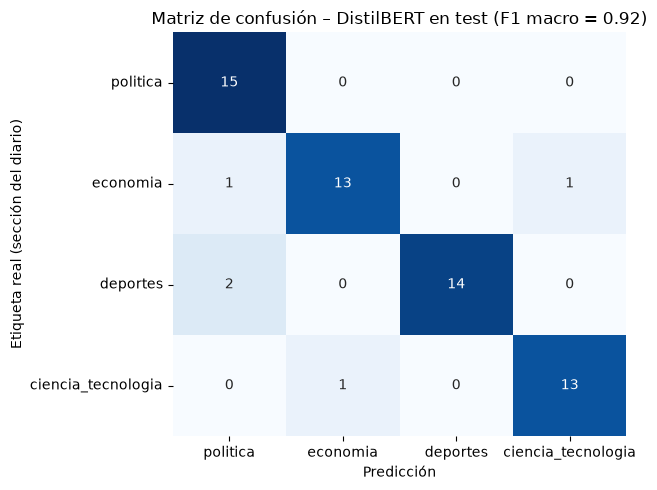

In [13]:
cm = confusion_matrix(test_df["etiqueta"], test_df["pred_ft"], labels=CATEGORIAS)
plt.figure(figsize=(6.5, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CATEGORIAS, yticklabels=CATEGORIAS, cbar=False)
plt.title(f"Matriz de confusión – DistilBERT en test (F1 macro = {ft_f1:.2f})")
plt.xlabel("Predicción")
plt.ylabel("Etiqueta real (sección del diario)")
plt.tight_layout()
plt.show()

In [14]:
print("F1 macro en test por medio:")
display(test_df.groupby("medio")[["etiqueta", "pred_ft"]].apply(
    lambda g: pd.Series({"n": len(g), "accuracy": accuracy_score(g["etiqueta"], g["pred_ft"]),
                         "f1_macro": f1_score(g["etiqueta"], g["pred_ft"], average="macro")})).round(3))
print("Errores del modelo en test:")
test_df.loc[test_df["etiqueta"] != test_df["pred_ft"], ["medio", "titular", "etiqueta", "pred_ft", "etiqueta_llm", "prob_ft"]]

F1 macro en test por medio:


,n,accuracy,f1_macro
medio,,,
El Comercio,31.0,0.903,0.905
La Republica,29.0,0.931,0.931


Errores del modelo en test:


,medio,titular,etiqueta,pred_ft,etiqueta_llm,prob_ft
122,El Comercio,"Justin Trudeau, exprimer ministro de Canadá, sobre crisis de turismo en EE.UU.: “No han sido muy buenos ha...",economia,politica,politica,0.970508
98,El Comercio,"Mourinho sorprende con mensaje sobre Vinícius: “Si estuviese en su lugar, probablemente no estaría aquí”",deportes,politica,deportes,0.966354
347,La Republica,Petroperú aclara las 1.639 observaciones de la Refinería Talara: no todas son fallas físicas ni condicione...,economia,ciencia_tecnologia,economia,0.509550
279,La Republica,"Aixa Vigil desborda felicidad tras presentación en Universitario: ""He sido hincha toda mi vida""",deportes,politica,deportes,0.965166
7,El Comercio,"iPhone Duo se agota a minutos de abierta su preventa, ahora disponibles a partir del 22 de enero",ciencia_tecnologia,economia,ciencia_tecnologia,0.588865


### Reflexión por categoría

| Categoría | F1 test | Lectura |
| :--- | :---: | :--- |
| **deportes** | **0.93** (precisión 1.00) | **Mejor desempeño.** Su vocabulario es casi exclusivo: nombres de clubes, "vs.", "partido", "goles", "Liga 1", "Copa Libertadores", marcadores (3-2). Cuando el modelo dice "deportes", acierta siempre. Sus 2 errores son titulares **centrados en una persona y una cita** ("Mourinho sorprende con mensaje sobre Vinícius: …", "Aixa Vigil: 'He sido hincha toda mi vida'"), estructura *personaje + declaración entre comillas* que en el corpus es típica de política. |
| **ciencia_tecnologia** | 0.93 | Léxico distintivo (IA, científicos, NASA, especie, Meta, iPhone). Falla cuando la noticia tecnológica se cuenta **en clave comercial**: "iPhone Duo se agota a minutos de abierta su preventa…" → economía ("se agota", "preventa", "disponibles a partir de"). |
| **politica** | 0.91 (recall 1.00, precisión 0.83) | Recupera todas las noticias políticas, pero **absorbe noticias de otras categorías**: todo titular con actores públicos o verbos de declaración ("afirma", "sostiene", "sobre…") tiende a caer aquí. |
| **economia** | **0.90** (recall 0.87) | **Peor desempeño.** La economía peruana se narra a través de **actores estatales** (Petroperú, MEF, Gobierno, exministros): "Justin Trudeau, exprimer ministro de Canadá, sobre crisis de turismo en EE.UU." es economía para el diario pero tiene toda la superficie léxica de política. Además, el modelo **hereda el sesgo del LLM maestro**: qwen2.5 etiquetó como `politica` 15 de las 100 noticias económicas, por lo que en train hay 84 ejemplos "políticos" en vez de 70. |

**Por medio:** F1 de 0.93 en La República y 0.91 en El Comercio (n≈30 cada uno, diferencia no concluyente).
Un factor posible: los titulares políticos de El Comercio son más largos (mediana de 112 caracteres frente a 96 en La República) y mezclan más actores y temas en una sola línea.

## 5. Comparativa y decisión

Se comparan los tres enfoques **sobre los mismos 40 titulares del test** usados en la línea base (comparación justa)
y, para LLM y DistilBERT, también sobre el **test completo**.

In [15]:
sub = test_df.loc[zs_df.index]
latencias = {}
t0 = time.perf_counter()
clasificador = pipeline("text-classification", model=str(DIR_MODELO), tokenizer=str(DIR_MODELO), device=-1)
for t in test_df["titular"]:
    clasificador(t)
latencias["ft"] = (time.perf_counter() - t0) / len(test_df) * 1000

tamano_ft = sum(f.stat().st_size for f in DIR_MODELO.glob("*.safetensors")) / 1e6
comparativa = pd.DataFrame([
    {"modelo": f"Zero-shot ({ZS_MODELO.split('/')[1]})",
     "F1 macro (40 test)": zs_f1, "Accuracy (40 test)": zs_acc,
     "F1 macro (test completo)": np.nan, "latencia CPU (ms/titular)": zs_latencia_ms,
     "tamaño / costo": "~440 MB · sin entrenamiento · 4 inferencias NLI por titular"},
    {"modelo": f"LLM débil (ollama/{MODELO_LLM})",
     "F1 macro (40 test)": f1_score(sub["etiqueta"], sub["etiqueta_llm"], average="macro"),
     "Accuracy (40 test)": accuracy_score(sub["etiqueta"], sub["etiqueta_llm"]),
     "F1 macro (test completo)": f1_score(test_df["etiqueta"], test_df["etiqueta_llm"], average="macro"),
     "latencia CPU (ms/titular)": llm_latencia_ms,
     "tamaño / costo": "~4.7 GB · 7.6 B parámetros · requiere servidor Ollama"},
    {"modelo": "DistilBERT fine-tuned (etiquetas LLM)",
     "F1 macro (40 test)": f1_score(sub["etiqueta"], sub["pred_ft"], average="macro"),
     "Accuracy (40 test)": accuracy_score(sub["etiqueta"], sub["pred_ft"]),
     "F1 macro (test completo)": ft_f1, "latencia CPU (ms/titular)": latencias["ft"],
     "tamaño / costo": f"~{tamano_ft:.0f} MB · 135 M parámetros · {minutos_entrenamiento:.1f} min de entrenamiento en CPU"},
]).set_index("modelo")
comparativa.round(3)

,F1 macro (40 test),Accuracy (40 test),F1 macro (test completo),latencia CPU (ms/titular),tamaño / costo
modelo,,,,,
Zero-shot (bert-base-spanish-wwm-cased-xnli),0.716,0.725,NaN,597.575,~440 MB · sin entrenamiento · 4 inferencias NLI por titular
LLM débil (ollama/qwen2.5:7b),0.923,0.925,0.949,6313.404,~4.7 GB · 7.6 B parámetros · requiere servidor Ollama
DistilBERT fine-tuned (etiquetas LLM),0.900,0.900,0.917,110.390,~541 MB · 135 M parámetros · 4.5 min de entrenamiento en CPU


In [16]:
metricas = {
    "fecha_evaluacion": datetime.now(timezone(timedelta(hours=-5))).strftime("%Y-%m-%d"),
    "modelo_base": MODELO_BASE, "modelo_llm": f"ollama/{MODELO_LLM}", "modelo_zero_shot": ZS_MODELO,
    "n_train": len(train_df), "n_val": len(val_df), "n_test": len(test_df),
    "test_accuracy": round(ft_acc, 4), "test_f1_macro": round(ft_f1, 4),
    "test_f1_por_clase": {c: round(reporte[c]["f1-score"], 4) for c in CATEGORIAS},
    "zero_shot_accuracy": round(zs_acc, 4), "zero_shot_f1_macro": round(zs_f1, 4),
    "llm_vs_seccion_f1_macro": round(llm_f1_total, 4),
    "llm_test_f1_macro": round(f1_score(test_df["etiqueta"], test_df["etiqueta_llm"], average="macro"), 4),
    "auditoria_acuerdos": acuerdos, "auditoria_total": len(auditoria),
    "auditoria_acuerdo_pct": acuerdo_pct,
    "latencia_ms": {"zero_shot": round(zs_latencia_ms), "llm": round(llm_latencia_ms), "fine_tuned": round(latencias["ft"])},
    "matriz_confusion": cm.tolist(),
}
(DIR_MODELO / "metricas.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=2), encoding="utf-8")
print("Resultados para la entrega:")
print(f"F1 Macro: {ft_f1:.2f} | Zero-shot: {zs_f1:.2f} | Acuerdo LLM-Humano: {acuerdos}/{len(auditoria)}")

Resultados para la entrega:
F1 Macro: 0.92 | Zero-shot: 0.72 | Acuerdo LLM-Humano: 18/20


### Decisión

| Criterio | Zero-shot | LLM débil (qwen2.5:7b) | DistilBERT fine-tuned |
| :--- | :---: | :---: | :---: |
| Precisión (F1 macro) | 0.72 – insuficiente | **0.95** (test completo) | 0.92 |
| Latencia CPU (medida en este notebook) | cientos de ms | 5–6 s | **decenas de ms** |
| Recursos | 440 MB | 4.7 GB + servidor Ollama | **541 MB, un solo proceso** |
| Determinismo / control | alto | medio (depende del prompt) | **alto** |

**Elegiría DistilBERT fine-tuned para un entorno real.** Pierde ~3 puntos de F1 frente al LLM (que además tuvo la
ventaja de leer la bajada al etiquetar), pero es **más de 50 veces más rápido** (ver la tabla anterior), ocupa **9 veces menos** y corre en
cualquier CPU dentro del mismo proceso que la app, sin servidor externo ni costo por consulta. Para un portal que
clasifica cientos de notas por hora, esa diferencia de latencia y costo pesa más que 3 puntos de F1.

El LLM no se descarta: es el **anotador** ideal. Una arquitectura en cascada aprovecharía ambos: DistilBERT
clasifica todo y solo los casos con probabilidad < 0.6 (frontera economía/política) se escalan al LLM; y el LLM
se usa periódicamente para re-etiquetar noticias nuevas y re-entrenar el modelo pequeño. El zero-shot queda
descartado: no supera el piso de calidad y es unas 5 veces más lento que el modelo ajustado.

**Respuesta a la pregunta guía:** sí. Con 400 titulares reales y etiquetas generadas por un LLM local —sin
anotación manual masiva— se obtuvo un clasificador ligero con **F1 macro de 0.92** en un test aislado, 20 puntos
por encima de la línea base zero-shot.